In [ ]:
#required library
!pip install ucimlrepo

In [ ]:
# Importiing the required libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Fetch datasets
cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

# Extract features and target
X = cdc_diabetes_health_indicators.data.features
y = cdc_diabetes_health_indicators.data.targets

# Display dataset metadata
print("DATASET METADATA")
print(cdc_diabetes_health_indicators.metadata)

# Display variable information
print("\nVARIABLE INFORMATION")
print(cdc_diabetes_health_indicators.variables)

DATASET METADATA
{'uci_id': 891, 'name': 'CDC Diabetes Health Indicators', 'repository_url': 'https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators', 'data_url': 'https://archive.ics.uci.edu/static/public/891/data.csv', 'abstract': 'The Diabetes Health Indicators Dataset contains healthcare statistics and lifestyle survey information about people in general along with their diagnosis of diabetes. The 35 features consist of some demographics, lab test results, and answers to survey questions for each patient. The target variable for classification is whether a patient has diabetes, is pre-diabetic, or healthy. ', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular', 'Multivariate'], 'num_instances': 253680, 'num_features': 21, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Sex', 'Age', 'Education Level', 'Income'], 'target_col': ['Diabetes_binary'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symb

In [ ]:
# Combine features and target
df = pd.concat([X, y], axis=1)

# Display the first five records
df.head()

#data sgape
print("Dataset shape:", df.shape)

#colum names
print("Dataset columns:")
print(df.columns.tolist())

#data tyoes
df.info()

#summary
df.describe().T





Dataset shape: (253680, 22)
Dataset columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                253680 non-null  int64
 1   HighChol              253680 non-null  int64
 2   CholCheck             253680 non-null  int64
 3   BMI                   253680 non-null  int64
 4   Smoker                253680 non-null  int64
 5   Stroke                253680 non-null  int64
 6   HeartDiseaseorAttack  253680 non-null  int64
 7   PhysActivity          253680 non-null  int64
 8   Fruits                253680 non-null  int64
 9   Veggies  

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


In [ ]:
#data inspection
df.isnull().sum()

#Check missing values
df.isnull().sum()

#total missing valuess
print("Total missing values:", df.isnull().sum().sum())

#duplicated records
print("Duplicate records:", df.duplicated().sum())

#unique values
for column in df.columns:
    print(column, ":", df[column].nunique())

#target distribution
print(df['Diabetes_binary'].value_counts())

print("\nTarget percentages:")
print(df['Diabetes_binary'].value_counts(normalize=True) * 100)



Total missing values: 0
Duplicate records: 24206
HighBP : 2
HighChol : 2
CholCheck : 2
BMI : 84
Smoker : 2
Stroke : 2
HeartDiseaseorAttack : 2
PhysActivity : 2
Fruits : 2
Veggies : 2
HvyAlcoholConsump : 2
AnyHealthcare : 2
NoDocbcCost : 2
GenHlth : 5
MentHlth : 31
PhysHlth : 31
DiffWalk : 2
Sex : 2
Age : 13
Education : 6
Income : 8
Diabetes_binary : 2
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target percentages:
Diabetes_binary
0    86.066698
1    13.933302
Name: proportion, dtype: float64


In [ ]:
#Dealing with the missing values
# Checking on missing values in each column
missing_values = df.isnull().sum()
print(missing_values)

# Calculate the overall % of missing values
missing_percentage = (df.isnull().sum().sum() /
                      (df.shape[0] * df.shape[1])) * 100

print("Percentage of missing values:", missing_percentage)

HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64
Percentage of missing values: 0.0


Duplicate records: 24206
Duplicate percentage: 9.54 %


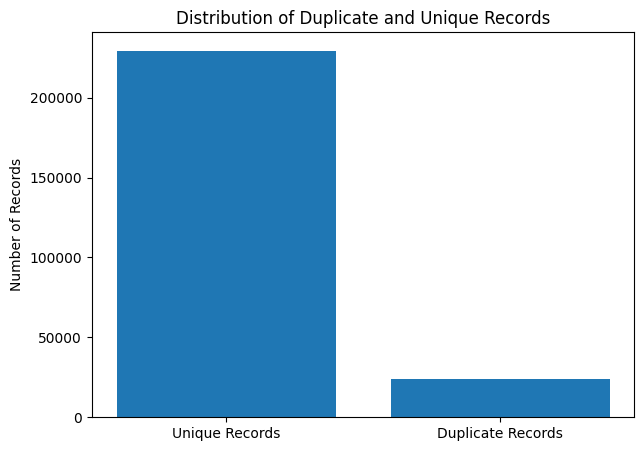

In [ ]:
#Handling duplicaterecords
# Calculate the duplicate records
duplicate_count = df.duplicated().sum()

# Calculate duplicate %
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")


#Visualizingg the duplicate distribution
plt.figure(figsize=(7, 5))

plt.bar(
    ['Unique Records', 'Duplicate Records'],
    [len(df) - duplicate_count, duplicate_count]
)

plt.title('Distribution of Duplicate and Unique Records')
plt.ylabel('Number of Records')

plt.show()


In [ ]:
#Removing ofduplicate records
df_clean = df.drop_duplicates(keep='first').copy()

# Compare the dataset sizes
print("Original dataset shape:", df.shape)
print("Dataset after removing duplicates:", df_clean.shape)

# Confirm removed duplicates completed
print("Remaining duplicates:", df_clean.duplicated().sum())

#compare the target distribution
# Target distribution before cleaning
print("Before removing duplicates:")
print(df['Diabetes_binary'].value_counts(normalize=True) * 100)

# Target distribution after cleaning
print("\nAfter removing duplicates:")
print(df_clean['Diabetes_binary'].value_counts(normalize=True) * 100)



Original dataset shape: (253680, 22)
Dataset after removing duplicates: (229474, 22)
Remaining duplicates: 0
Before removing duplicates:
Diabetes_binary
0    86.066698
1    13.933302
Name: proportion, dtype: float64

After removing duplicates:
Diabetes_binary
0    84.705457
1    15.294543
Name: proportion, dtype: float64


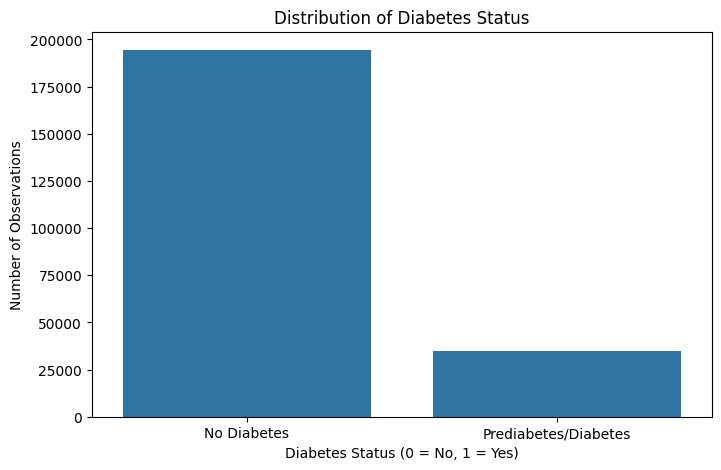

Diabetes_binary
0    84.705457
1    15.294543
Name: proportion, dtype: float64


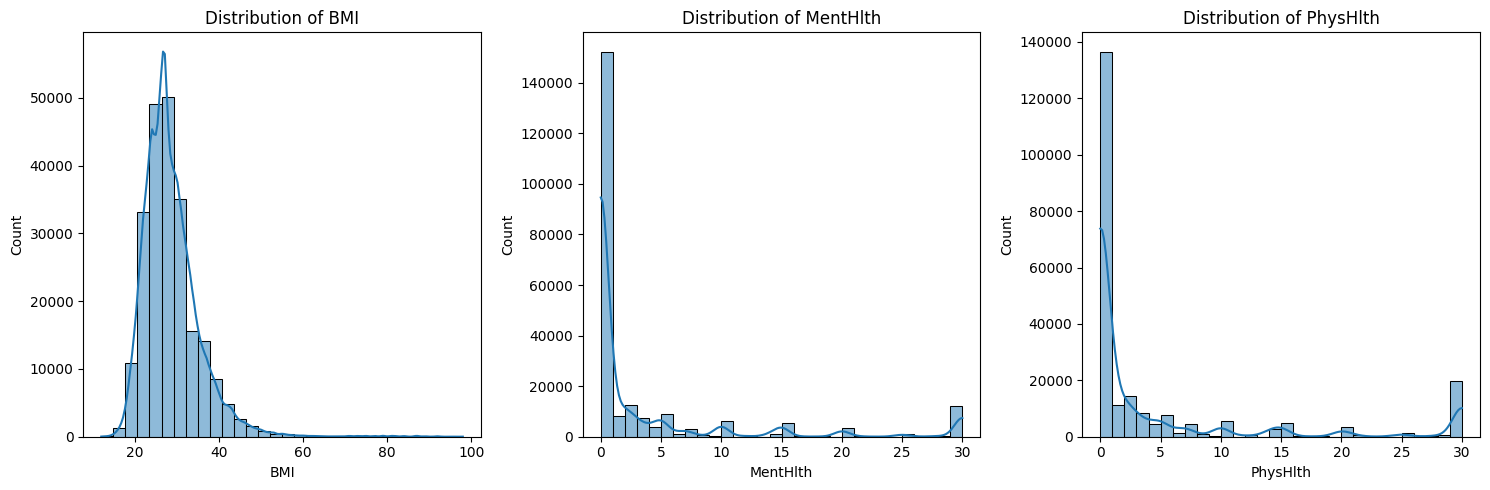

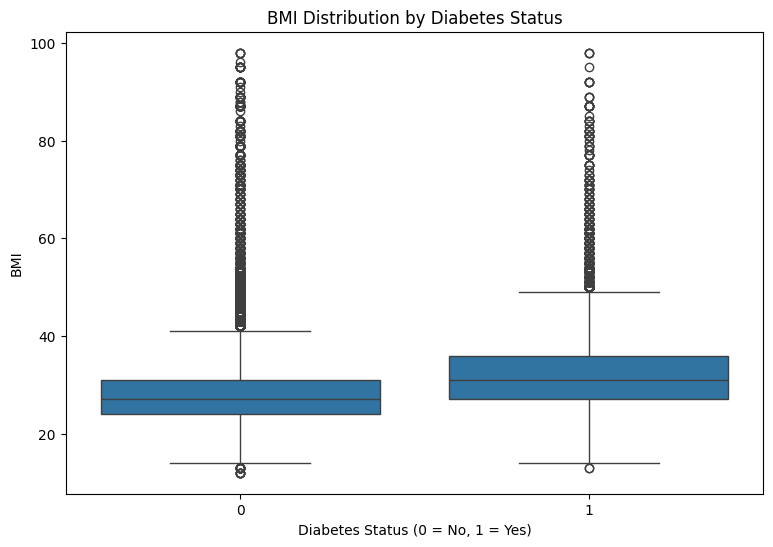

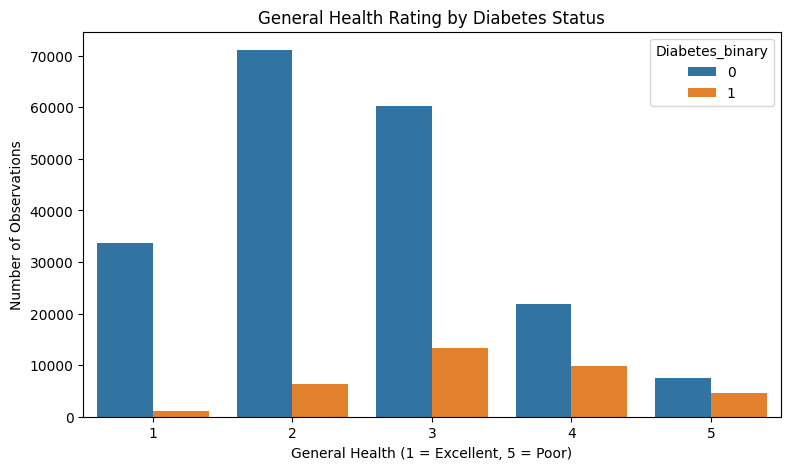

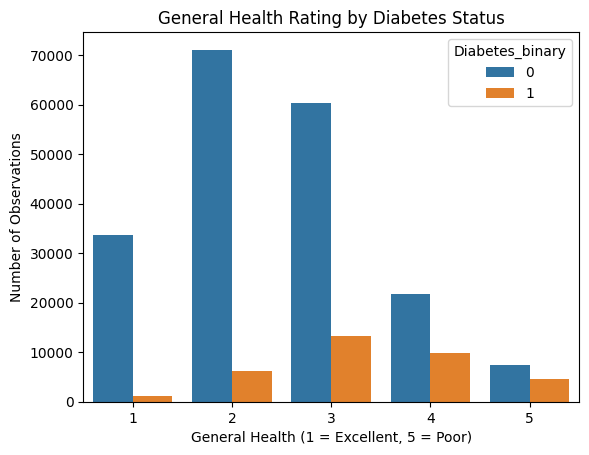

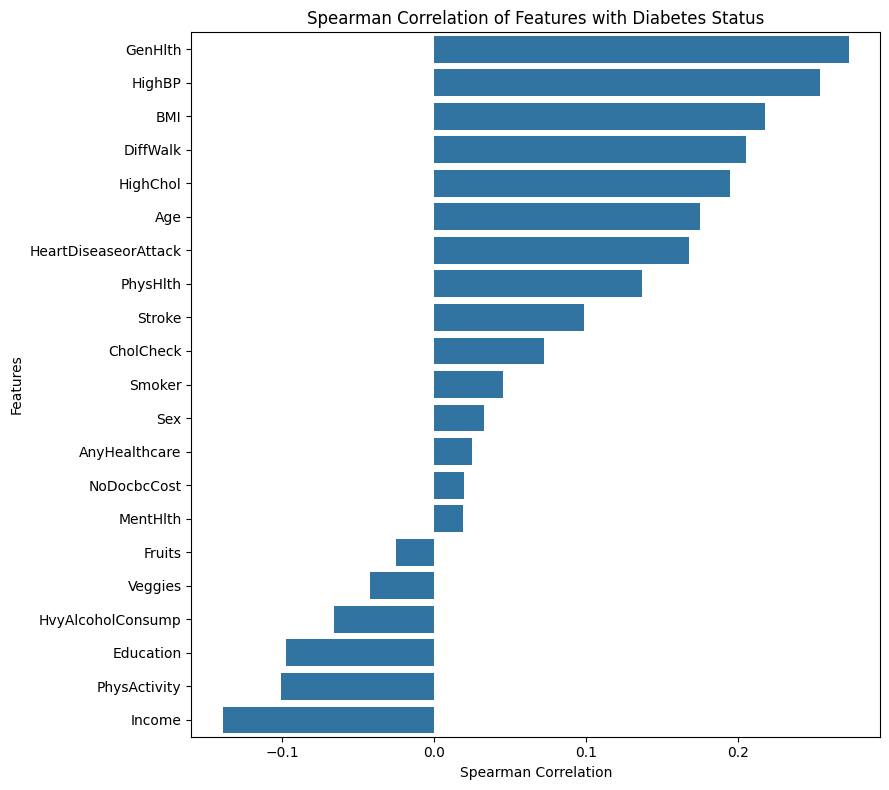

Q1: 24.0
Q3: 32.0
IQR: 8.0
Lower boundary: 12.0
Upper boundary: 44.0
Potential BMI outliers: 5638


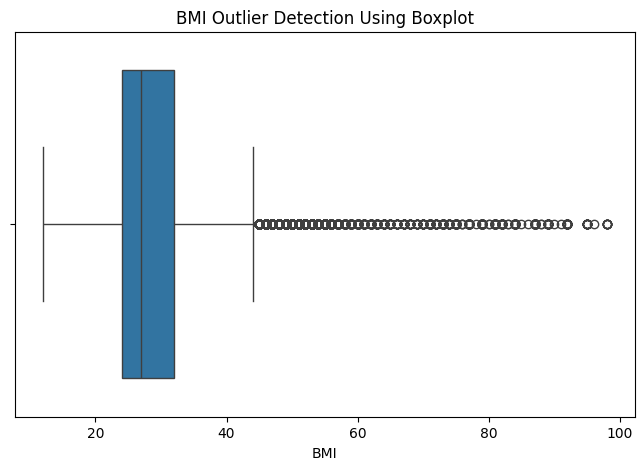

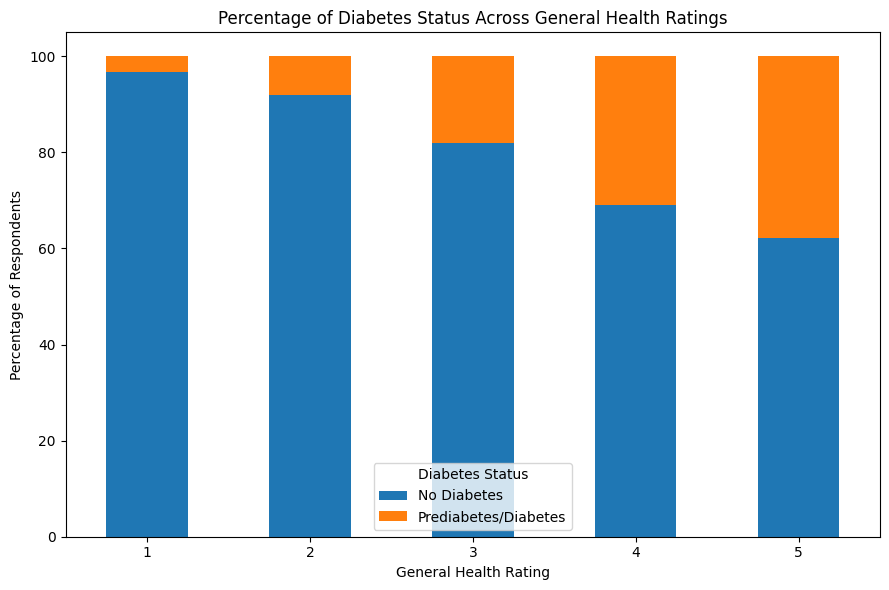

In [ ]:
#Exploratory Data Analysis (EDA)
#Visualization code
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Diabetes_binary'
)
plt.title('Distribution of Diabetes Status')
plt.xlabel('Diabetes Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Observations')

plt.xticks([0, 1], ['No Diabetes', 'Prediabetes/Diabetes'])

plt.show()

#Display the percentages

target_percentage = (
    df_clean['Diabetes_binary']
    .value_counts(normalize=True) * 100
)
print(target_percentage)

#Distribution of numerical health variables
numerical_features = ['BMI', 'MentHlth', 'PhysHlth']

plt.figure(figsize=(15, 5))
for i, column in enumerate(numerical_features, 1):

    plt.subplot(1, 3, i)

    sns.histplot(
        data=df_clean,
        x=column,
        bins=30,
        kde=True
    )
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)

plt.tight_layout()
plt.show()

#Relationship between BMI and diabetes status
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x='Diabetes_binary',
    y='BMI'
)

plt.title('BMI Distribution by Diabetes Status')
plt.xlabel('Diabetes Status (0 = No, 1 = Yes)')
plt.ylabel('BMI')

plt.show()

#Relationship between general health and diabetes
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='GenHlth',
    hue='Diabetes_binary'
)

plt.title('General Health Rating by Diabetes Status')
plt.xlabel('General Health (1 = Excellent, 5 = Poor)')
plt.ylabel('Number of Observations')

plt.show()

#plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='GenHlth',
    hue='Diabetes_binary'
)

plt.title('General Health Rating by Diabetes Status')
plt.xlabel('General Health (1 = Excellent, 5 = Poor)')
plt.ylabel('Number of Observations')

plt.show()


#Correlation analysis

# Calculate Spearman correlation
correlation = df_clean.corr(method='spearman')

# Plot correlation with the target variable
target_corr = correlation['Diabetes_binary'].drop(
    'Diabetes_binary'
).sort_values(ascending=False)

plt.figure(figsize=(9, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title('Spearman Correlation of Features with Diabetes Status')
plt.xlabel('Spearman Correlation')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

#Outlier detection#
# Calculate IQR for BMI
Q1 = df_clean['BMI'].quantile(0.25)
Q3 = df_clean['BMI'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
bmi_outliers = df_clean[
    (df_clean['BMI'] < lower_bound) |
    (df_clean['BMI'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Potential BMI outliers:", len(bmi_outliers))

#Visualize potential outliers
plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean['BMI'])

plt.title('BMI Outlier Detection Using Boxplot')
plt.xlabel('BMI')

plt.show()



# Calculate percentage distribution within each health category
health_percentage = pd.crosstab(
    df_clean['GenHlth'],
    df_clean['Diabetes_binary'],
    normalize='index'
) * 100

# Plot percentage distribution
health_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6)
)

plt.title('Percentage of Diabetes Status Across General Health Ratings')
plt.xlabel('General Health Rating')
plt.ylabel('Percentage of Respondents')

plt.legend(
    ['No Diabetes', 'Prediabetes/Diabetes'],
    title='Diabetes Status'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



Features shape: (253680, 21)
Target shape: (253680,)
TRAINING SET
Features: (177576, 21)
Target: (177576,)

VALIDATION SET
Features: (38052, 21)
Target: (38052,)

TESTING SET
Features: (38052, 21)
Target: (38052,)
Training target distribution:
Diabetes_binary
0    86.066811
1    13.933189
Name: proportion, dtype: float64

Validation target distribution:
Diabetes_binary
0    86.066435
1    13.933565
Name: proportion, dtype: float64

Testing target distribution:
Diabetes_binary
0    86.066435
1    13.933565
Name: proportion, dtype: float64


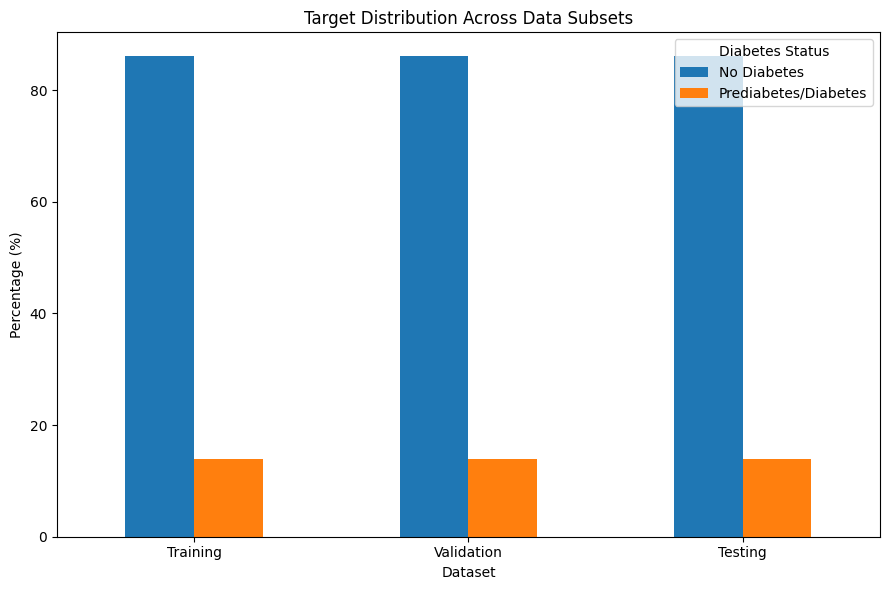

In [ ]:
#Stage 2: Data Splitting
# Retaining the originaldataset
df_final = df.copy()

# Separate independent and dependent variables
X = df_final.drop('Diabetes_binary', axis=1)

y = df_final['Diabetes_binary']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

#first split.

from sklearn.model_selection import train_test_split

# First split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

#Verify the dataset sizes

# Display dataset dimensions
print("TRAINING SET")
print("Features:", X_train.shape)
print("Target:", y_train.shape)

print("\nVALIDATION SET")
print("Features:", X_val.shape)
print("Target:", y_val.shape)

print("\nTESTING SET")
print("Features:", X_test.shape)
print("Target:", y_test.shape)


#Examine target distribution across the three subsets

# Display target percentages
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


#visualize the distributions.
# Combine target distributions
distribution = pd.DataFrame({
    'Training': y_train.value_counts(normalize=True),
    'Validation': y_val.value_counts(normalize=True),
    'Testing': y_test.value_counts(normalize=True)
}) * 100

# Plot the distributions
distribution.T.plot(
    kind='bar',
    figsize=(9, 6)
)

plt.title('Target Distribution Across Data Subsets')
plt.xlabel('Dataset')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=0)
plt.legend(
    ['No Diabetes', 'Prediabetes/Diabetes'],
    title='Diabetes Status'
)

plt.tight_layout()
plt.show()





In [ ]:
#Stage 3: Model Selection and Development

# Import preprocessing library
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and testing data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_val_scaled = pd.DataFrame(
    X_val_scaled,
    columns=X_val.columns,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled validation data:", X_val_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)





Scaled training data: (177576, 21)
Scaled validation data: (38052, 21)
Scaled testing data: (38052, 21)


In [ ]:
#Developing Model 1: Logistic Regression
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    C=1.0,
    solver='lbfgs',
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Display model configuration
print(logistic_model)

#Model 2: Random Forest Classifier
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Display model configuration
print(random_forest_model)


#Model 3: Artificial Neural Network
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

# Set random seeds
tf.random.set_seed(42)
np.random.seed(42)

# Initialize NeuralNetwork
neural_network_model = Sequential([

    # Input layer
    Input(shape=(X_train_scaled.shape[1],)),

    # First hidden layer
    Dense(64, activation='relu'),

    # Dropout layer
    Dropout(0.3),
    # Second hidden layer
    Dense(32, activation='relu'),
    # Dropout layer
    Dropout(0.2),
    # Output layer
    Dense(1, activation='sigmoid')
])

# Compile the Neural Network
neural_network_model.compile(

    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

# Displayy network architecture
neural_network_model.summary()

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=200, n_jobs=-1, random_state=42)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#STAGE 4: MODEL TRAINING AND HYPERPARAMETER OPTIMIZATION
#Import the required libraries
# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Hyperparameter optimization
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

# Class imbalance handling
from sklearn.utils.class_weight import compute_class_weight

# Neural Network callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

# Additional libraries
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


#Model 1: Training Logistic Regression
# Train Logistic Regression
logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression training completed.")

#validation predictions
# Predict validation classes
logistic_val_pred = logistic_model.predict(
    X_val_scaled
)

# Predict validation probabilities
logistic_val_prob = logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Logistic Regression validation predictions completed.")

#Evaluate Logistic Regression
# Calculate validation metrics
logistic_accuracy = accuracy_score(
    y_val, logistic_val_pred
)

logistic_precision = precision_score(
    y_val, logistic_val_pred,
    zero_division=0
)
logistic_recall = recall_score(
    y_val, logistic_val_pred,
    zero_division=0
)
logistic_f1 = f1_score(
    y_val, logistic_val_pred,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_val, logistic_val_prob
)

# Display results
print("LOGISTIC REGRESSION - VALIDATION RESULTS")

print("Accuracy:", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall:", logistic_recall)
print("F1-score:", logistic_f1)
print("ROC-AUC:", logistic_auc)

#Model 2: Training Random Forest Classifier
# Train Random Forest
random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

#validation predictions
# Predict validation classes
rf_val_pred = random_forest_model.predict(
    X_val
)

# Predict validation probabilities
rf_val_prob = random_forest_model.predict_proba(
    X_val
)[:, 1]

print("Random Forest validation predictions completed.")

#Evaluate Random Forest
# Calculate validation metrics
rf_accuracy = accuracy_score(
    y_val, rf_val_pred
)

rf_precision = precision_score(
    y_val, rf_val_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_val, rf_val_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_val, rf_val_pred,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_val, rf_val_prob
)

# Display results
print("RANDOM FOREST - VALIDATION RESULTS")

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-score:", rf_f1)
print("ROC-AUC:", rf_auc)


#Hyperparameter optimization
# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define parameter distribution
logistic_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs']
}

# Initialize RandomizedSearchCV
logistic_search = RandomizedSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    param_distributions=logistic_params,
    n_iter=5,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter optimization
logistic_search.fit(
    X_train_scaled,
    y_train
)

# Display optimal parameters
print("Best Logistic Regression Parameters:")
print(logistic_search.best_params_)

print("\nBest Cross-validation ROC-AUC:")
print(logistic_search.best_score_)

# Store optimized Logistic Regression
best_logistic_model = logistic_search.best_estimator_


#Optimize Random Forest
# Define Random Forest parameter distribution
rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20],
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

# Initialize RandomizedSearchCV
rf_search = RandomizedSearchCV(

    estimator=RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ),
    param_distributions=rf_params,

    n_iter=5,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter optimization
rf_search.fit(
    X_train,
    y_train
)

# Display optimal parameters
print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-validation ROC-AUC:")
print(rf_search.best_score_)

#Retrieve the optimized Random Forest:
# Store optimized Random Forest
best_rf_model = rf_search.best_estimator_


#Evaluate optimized traditional models
# Logistic Regression predictions
best_logistic_pred = best_logistic_model.predict(
    X_val_scaled
)
best_logistic_prob = best_logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

# Random Forest predictions
best_rf_pred = best_rf_model.predict(
    X_val
)
best_rf_prob = best_rf_model.predict_proba(
    X_val
)[:, 1]

#Calculate their performance
# Function for calculating classification metrics
def evaluate_model(y_true, y_pred, y_prob):

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }


# Evaluate optimized models
logistic_results = evaluate_model(
    y_val,
    best_logistic_pred,
    best_logistic_prob
)

rf_results = evaluate_model(
    y_val,
    best_rf_pred,
    best_rf_prob
)

print("Optimized Logistic Regression:")
print(logistic_results)

print("\nOptimized Random Forest:")
print(rf_results)



Logistic Regression training completed.
Logistic Regression validation predictions completed.
LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy: 0.7301850099863345
Precision: 0.3095512082853855
Recall: 0.7610335722368917
F1-score: 0.4400937994219338
ROC-AUC: 0.8214927853812907
Random Forest training completed.
Random Forest validation predictions completed.
RANDOM FOREST - VALIDATION RESULTS
Accuracy: 0.7645064648375907
Precision: 0.33560966843382156
Recall: 0.7044511505092418
F1-score: 0.4546284462296878
ROC-AUC: 0.8231498584719579
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Logistic Regression Parameters:
{'solver': 'lbfgs', 'C': 0.01}

Best Cross-validation ROC-AUC:
0.8230443102602919
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Random Forest Parameters:
{'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': 20}

Best Cross-validation ROC-AUC:
0.8268692655668278
Optimized Logistic Regressio

Neural Network Class Weights:
{np.int64(0): np.float64(0.5809440307784917), np.int64(1): np.float64(3.5885538760003235)}
Epoch 1/50
347/347 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6960 - auc: 0.7965 - loss: 0.5445 - precision: 0.2823 - recall: 0.7664 - val_accuracy: 0.7016 - val_auc: 0.8229 - val_loss: 0.5212 - val_precision: 0.2928 - val_recall: 0.8065 - learning_rate: 0.0010
Epoch 2/50
347/347 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7040 - auc: 0.8176 - loss: 0.5184 - precision: 0.2939 - recall: 0.8020 - val_accuracy: 0.7051 - val_auc: 0.8253 - val_loss: 0.5173 - val_precision: 0.2960 - val_recall: 0.8103 - learning_rate: 0.0010
Epoch 3/50
347/347 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7074 - auc: 0.8212 - loss: 0.5138 - precision: 0.2969 - recall: 0.8044 - val_accuracy: 0.7109 - val_auc: 0.8263 - val_loss: 0.5115 - val_precision: 0.2997 - val_recall: 0.8040 - learning_rate: 0.0010
Epoch 4/50
347/347 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7080 - auc: 0.8

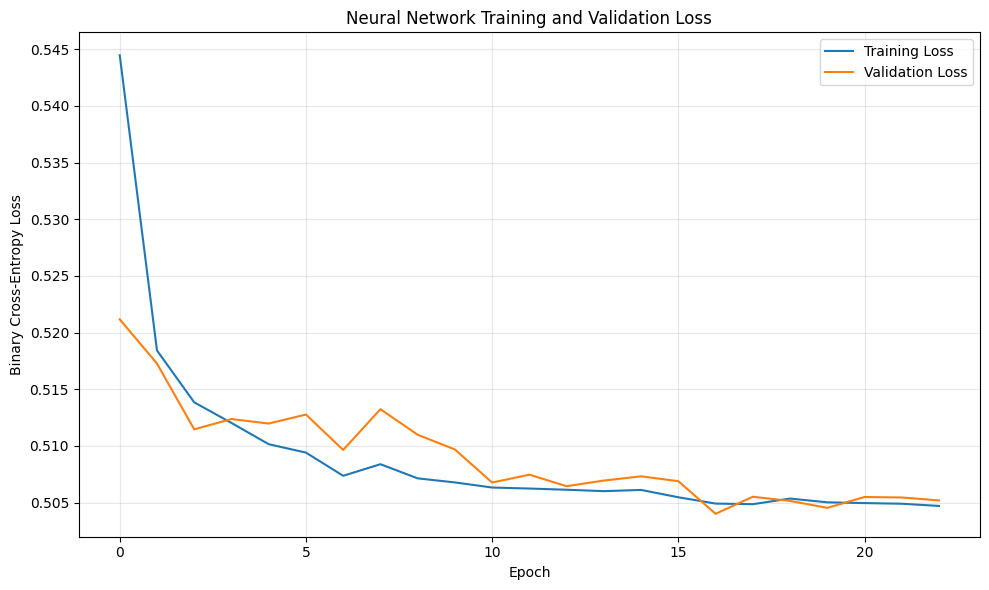

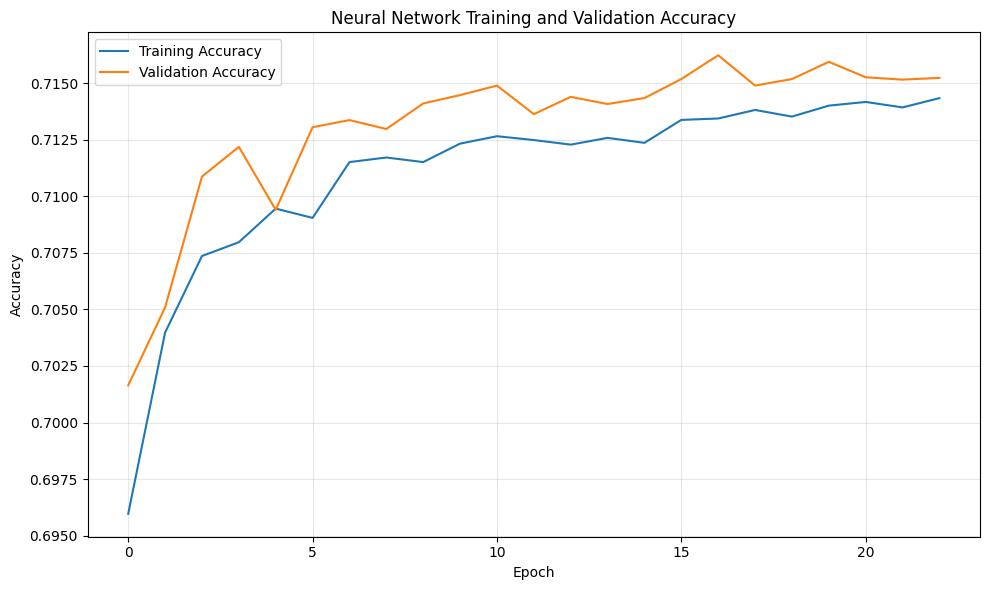

1190/1190 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
NEURAL NETWORK -- VALIDATION RESULTS
Accuracy: 0.7162
Precision: 0.3030
Recall: 0.7974
F1-score: 0.4392
ROC-AUC: 0.8281
5550/5550 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
            Accuracy  Precision  Recall  F1-score  ROC-AUC
Training      0.7192     0.3065  0.8038    0.4437   0.8327
Validation    0.7162     0.3030  0.7974    0.4392   0.8281
MODEL VALIDATION PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.7301,0.3094,0.7608,0.4399,0.8215
Random Forest,0.7645,0.3374,0.7161,0.4587,0.8245
Neural Network,0.7162,0.3030,0.7974,0.4392,0.8281


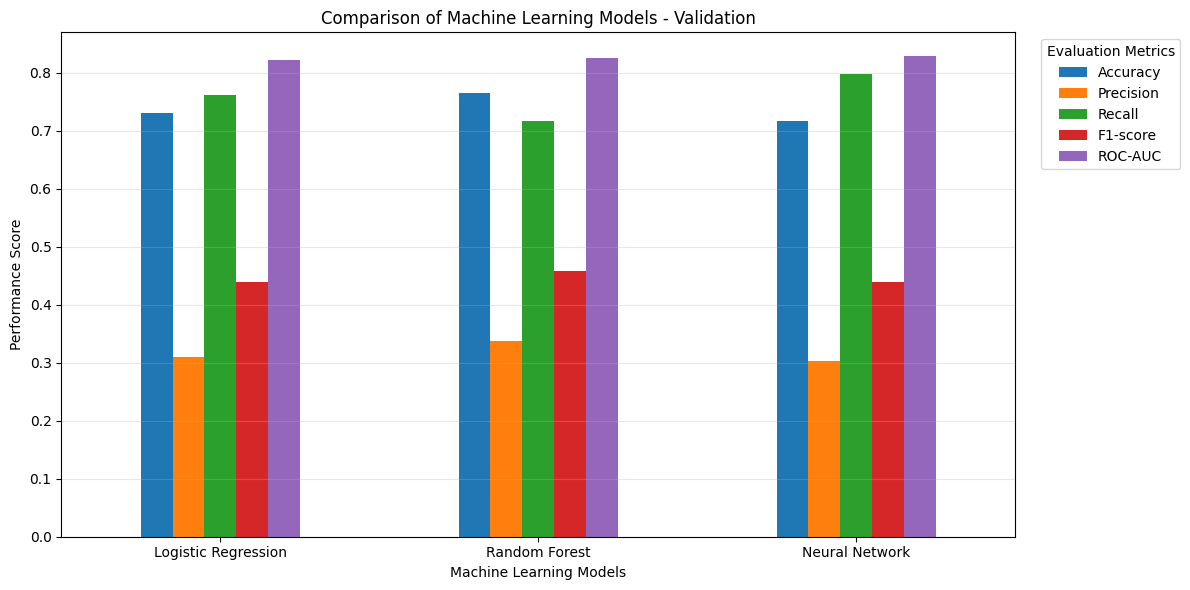

In [ ]:
#Model 3: Neural Network Training
#Addressing class imbalance

# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

# Convert weights into a dictionary
class_weights = dict(
    zip(classes, weights)
)

print("Neural Network Class Weights:")
print(class_weights)

#Configuring early stopping
# Early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)


#a learning-rate reduction callback.
# Reduce learning rate when validation loss stops improving
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

#Train the Neural Network

# Train Neural Network
history = neural_network_model.fit(

    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=50,
    batch_size=512,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

print("Neural Network training completee.")


#Training and validation loss curves
# Extract loss values
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Plot loss curves
plt.figure(figsize=(10, 6))

plt.plot(
    train_loss,
    label='Training Loss'
)

plt.plot(
    val_loss,
    label='Validation Loss'
)

plt.title('Neural Network Training and Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Training and validation accuracy curves

# Extractingg accuracy values
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Plot accuracy curves
plt.figure(figsize=(10, 6))

plt.plot(
    train_accuracy,
    label='Training Accuracy'
)

plt.plot(
    val_accuracy,
    label='Validation Accuracy'
)

plt.title('Neural Network Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


#Evaluate Neural Network performance
# Generate validation probabilities
nn_val_prob = neural_network_model.predict(
    X_val_scaled
).ravel()

# Convert probabilities into binary predictions
nn_val_pred = (nn_val_prob >= 0.5).astype(int)

# Calculate validation metrics
nn_results = evaluate_model(
    y_val,
    nn_val_pred,
    nn_val_prob
)

print("NEURAL NETWORK -- VALIDATION RESULTS")

for metric, value in nn_results.items():
    print(f"{metric}: {value:.4f}")

#Examining NeuralNetwork overfitting and underfitting

# Training predictions
nn_train_prob = neural_network_model.predict(
    X_train_scaled
).ravel()

nn_train_pred = (
    nn_train_prob >= 0.5
).astype(int)

# Evaluate training performance
nn_train_results = evaluate_model(
    y_train,
    nn_train_pred,
    nn_train_prob
)

# Display training and validation performance
nn_comparison = pd.DataFrame(
    [nn_train_results, nn_results],
    index=['Training', 'Validation']
)

print(nn_comparison.round(4))


#Compare the three models using validation results
# Collect validation results
validation_results = pd.DataFrame({

    'Logistic Regression': evaluate_model(
        y_val,
        best_logistic_pred,
        best_logistic_prob
    ),

    'Random Forest': evaluate_model(
        y_val,
        best_rf_pred,
        best_rf_prob
    ),

    'Neural Network': nn_results

}).T

# Display comparison
print("MODEL VALIDATION PERFORMANCE COMPARISON")

display(validation_results.round(4))

#Visualize model performance
# Plot comparison of validation metrics
validation_results.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Machine Learning Models - Validation')

plt.xlabel('Machine Learning Models')
plt.ylabel('Performance Score')

plt.xticks(rotation=0)

plt.legend(
    title='Evaluation Metrics',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()




1190/1190 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Test predictions generated.
FINAL TEST PERFORMANCE


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.7334,0.3129,0.7633,0.4438,0.8216
Random Forest,0.7680,0.3406,0.7103,0.4604,0.8267
Neural Network,0.7196,0.3066,0.8023,0.4436,0.8297


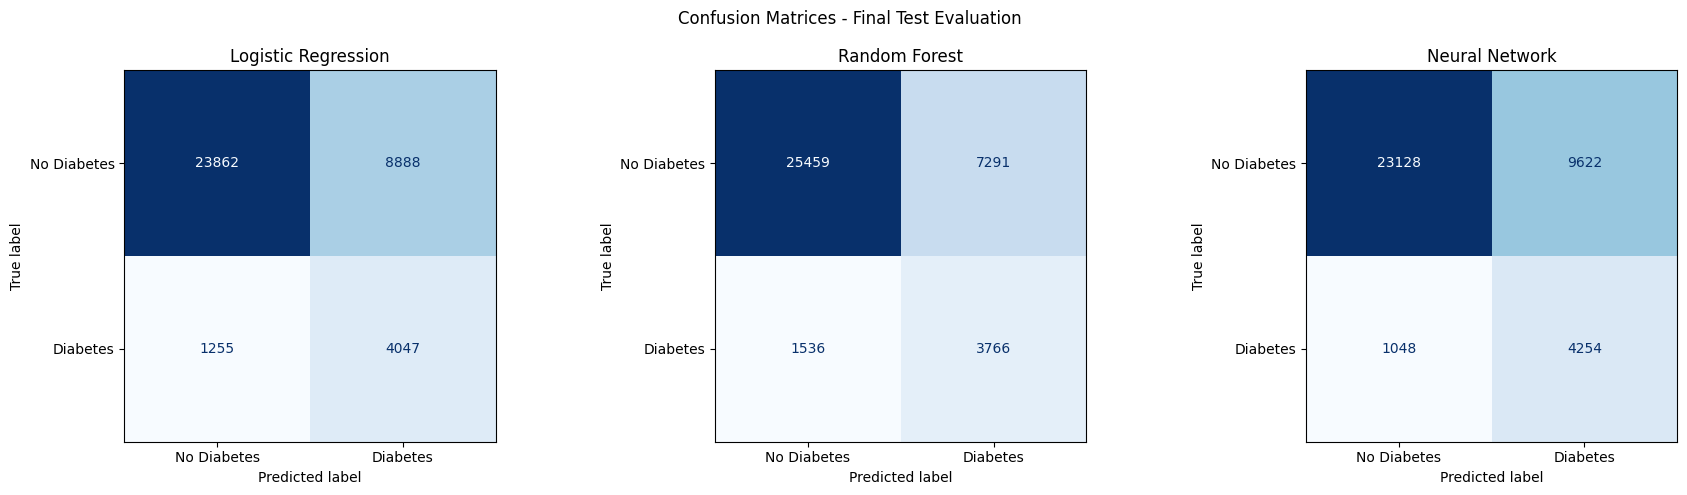

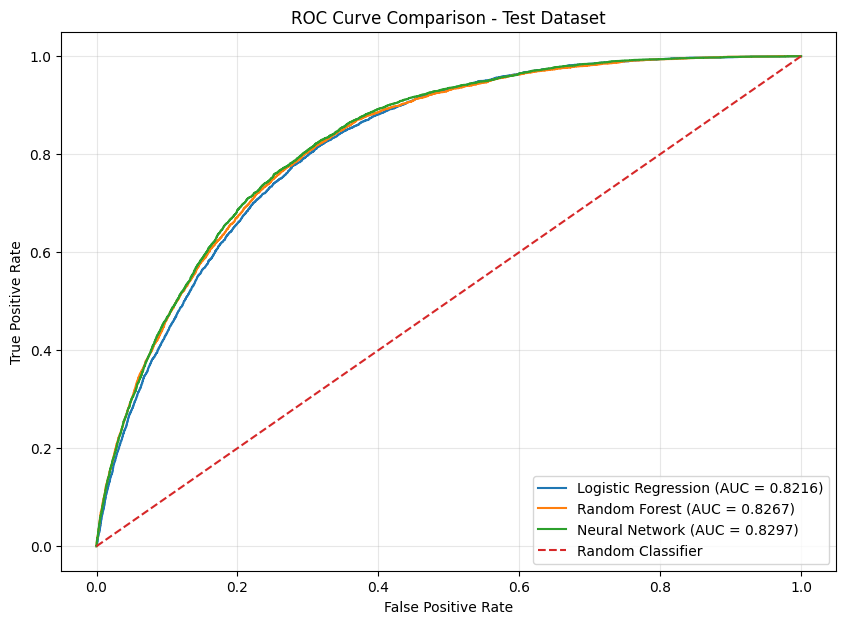

In [ ]:
#STAGE 5 – MODEL FINAL EVALUATION AND COMPARISON
#predictions using the test dataset
# Generate Logistic Regression predictions
lr_test_prob = best_logistic_model.predict_proba(
    X_test_scaled
)[:, 1]
lr_test_pred = (lr_test_prob >= 0.5).astype(int)

# Generate Random Forest predictions
rf_test_prob = best_rf_model.predict_proba(
    X_test
)[:, 1]
rf_test_pred = (rf_test_prob >= 0.5).astype(int)


# create Neural Network predictions
nn_test_prob = neural_network_model.predict(
    X_test_scaled
).ravel()
nn_test_pred = (nn_test_prob >= 0.5).astype(int)

print("Test predictions generated.")

#Calculate final test evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Function to calculate test metrics
def calculate_test_metrics(y_true, y_pred, y_prob):

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_true, y_prob
        )
    }


# Evaluate all models
test_results = pd.DataFrame({
    'Logistic Regression': calculate_test_metrics(
        y_test, lr_test_pred, lr_test_prob
    ),
    'Random Forest': calculate_test_metrics(
        y_test, rf_test_pred, rf_test_prob
    ),
    'Neural Network': calculate_test_metrics(
        y_test, nn_test_pred, nn_test_prob
    )
}).T


print("FINAL TEST PERFORMANCE")
display(test_results.round(4))

#Generating confusion matrices
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Predictions from all models
models_predictions = {
    'Logistic Regression': lr_test_pred,
    'Random Forest': rf_test_pred,
    'Neural Network': nn_test_pred
}

# Plot confusion matrices
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5)
)

for ax, (name, predictions) in zip(
    axes, models_predictions.items()
):

    cm = confusion_matrix(
        y_test, predictions
    )
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            'No Diabetes',
            'Diabetes'
        ]
    )
    disp.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False
    )
    ax.set_title(name)

plt.suptitle(
    'Confusion Matrices - Final Test Evaluation'
)

plt.tight_layout()
plt.show()

#Plot ROC curves for all three models
from sklearn.metrics import roc_curve, auc

# Store prediction probabilities
models_probabilities = {
    'Logistic Regression': lr_test_prob,
    'Random Forest': rf_test_prob,
    'Neural Network': nn_test_prob
}

plt.figure(figsize=(10, 7))

for name, probabilities in models_probabilities.items():
    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.4f})'
    )

# Random classification reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison - Test Dataset')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

